# Project 1: Forecasting Weekly Sales at NileMart
**CLS eLearning · Machine Learning · Supervised Learning**

**Algorithm:** Linear Regression &nbsp;|&nbsp; **Lecture slides:** 9 to 19

---
### The business case
You have just joined **NileMart**, a fictional Egyptian grocery chain, as a junior data analyst. Before each week, the marketing manager decides the ad budget and the discount level, and she asks you one question:

> *"If I spend more on ads next week, how much will sales grow, and is it worth the money?"*

You have three years of weekly data. By the end, you will give her a clear recommendation backed by a model.

### What you will practice
- Cleaning data before modeling
- Splitting time data the right way
- Building simple and multiple linear regression
- Evaluating with MAE, RMSE and R²
- Spotting a misleading slope and data leakage
- Turning a coefficient into a business decision

### The data: `nilemart_weekly_sales.csv`
| Column | Meaning |
|---|---|
| `week` | Week number, from 1 to 156 |
| `ad_spend_k` | Ad spend that week, in EGP thousand |
| `discount_pct` | Average discount that week, in % |
| `is_holiday_period` | 1 for Ramadan, Eid and year-end weeks, otherwise 0 |
| `competitor_promo` | 1 if the main competitor ran a promotion, otherwise 0 |
| `store_visitors_k` | Store visitors that week, in thousands |
| `sales_k` | **Target:** sales that week, in EGP thousand |

### How to work through this project
Each task follows the same pattern:

| You see | What to do |
|---|---|
| **Goal, Why it matters, Steps** | Read them first. They guide you, but they do not give you the code. |
| **Hint** | Click it only if you are stuck. Most hints point to a slide in the lecture. |
| **`# YOUR CODE HERE` cell** | Write your solution here. Use the exact variable names listed, because the checks look for them. |
| **Self-check cell** | Run it as given. ✅ means your result looks right, ❌ means review it, ⏳ means it is not done yet. |
| **✍️ Question** | Write your answer in your own words in the cell under it. Double-click that cell to edit it. |

Run the cells in order, from top to bottom. To restart cleanly, use **Kernel > Restart & Run All**.

> **Using Google Colab?** Upload the CSV file first using the folder icon on the left.

## Setup
Run this cell first. It loads the tools you need and the `check` function.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn import metrics as M

def check(name, test, tip="Re-read the steps above and try again."):
    """Runs one self-check. It only tests your result, it never shows the solution."""
    try:
        passed = bool(test())
    except NameError as e:
        print(f"⏳ {name}: not done yet ({e})"); return
    except Exception as e:
        print(f"❌ {name}: {type(e).__name__}: {e}"); return
    print(f"✅ {name}" if passed else f"❌ {name}. {tip}")

print("Setup complete")

Setup complete


---
## Task 1: Load and explore the data

**Goal:** Get to know the data before you model anything.

**Why it matters:** Most project failures start with data nobody looked at.

**Steps:**
1. Load the CSV file into a DataFrame named `df`.
2. Display its shape and first rows.
3. Display summary statistics.
4. Count the missing values in each column.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Use `pd.read_csv`, `.shape`, `.head()`, `.describe()` and `.isna().sum()`.

</details>

In [2]:
# Task 1: Load and explore the data
# Create: df
df = pd.read_csv("nilemart_weekly_sales.csv")   # in Colab, upload the CSV first

print("Shape:", df.shape)
display(df.head())
display(df.describe())
print(df.isna().sum())

Shape: (156, 7)


,week,ad_spend_k,discount_pct,is_holiday_period,competitor_promo,store_visitors_k,sales_k
0,1,64.3,5,0,1,35.5,297.0
1,2,47.0,0,0,0,29.9,250.7
2,3,62.9,0,0,1,33.2,291.2
3,4,98.6,5,0,0,58.3,489.9
4,5,97.7,15,0,0,62.0,522.7


,week,ad_spend_k,discount_pct,is_holiday_period,competitor_promo,store_visitors_k,sales_k
count,156.000000,151.000000,156.000000,156.000000,156.000000,156.000000,156.000000
mean,78.500000,80.454967,6.602564,0.179487,0.275641,50.478846,452.516667
std,45.177428,25.973280,6.116798,0.384996,0.448276,12.369588,322.337117
min,1.000000,40.200000,0.000000,0.000000,0.000000,24.900000,31.500000
25%,39.750000,59.550000,0.000000,0.000000,0.000000,41.575000,356.400000
50%,78.500000,78.000000,5.000000,0.000000,0.000000,48.550000,411.300000
75%,117.250000,98.700000,10.000000,0.000000,1.000000,58.350000,498.225000
max,156.000000,147.100000,20.000000,1.000000,1.000000,82.000000,4215.000000


week                 0
ad_spend_k           5
discount_pct         0
is_holiday_period    0
competitor_promo     0
store_visitors_k     0
sales_k              0
dtype: int64


In [3]:
# Self-check: just run this cell
check("Data loaded with 156 rows and 7 columns", lambda: df.shape == (156, 7))

✅ Data loaded with 156 rows and 7 columns


**✍️ Question 1:** Which column has missing values, and how many? Look at the minimum and maximum of `sales_k`. What looks wrong?

In [4]:
# Only columns that have missing values
missing = df.isna().sum()
print(missing[missing > 0])

ad_spend_k    5
dtype: int64


In [5]:
df.describe()['sales_k']

count     156.000000
mean      452.516667
std       322.337117
min        31.500000
25%       356.400000
50%       411.300000
75%       498.225000
max      4215.000000
Name: sales_k, dtype: float64

In [6]:
# Outlier check with the IQR rule (skip the week index and 0/1 flags)
cols = ["ad_spend_k", "discount_pct", "store_visitors_k", "sales_k"]

for col in cols:
    s = df[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df[(df[col] < lo) | (df[col] > hi)]
    print(f"{col}: bounds [{lo:.1f}, {hi:.1f}], outliers: {len(out)}")
    if len(out):
        print(out[["week", col]])

ad_spend_k: bounds [0.8, 157.4], outliers: 0
discount_pct: bounds [-15.0, 25.0], outliers: 0
store_visitors_k: bounds [16.4, 83.5], outliers: 0
sales_k: bounds [143.7, 711.0], outliers: 2
    week  sales_k
44    45     31.5
96    97   4215.0


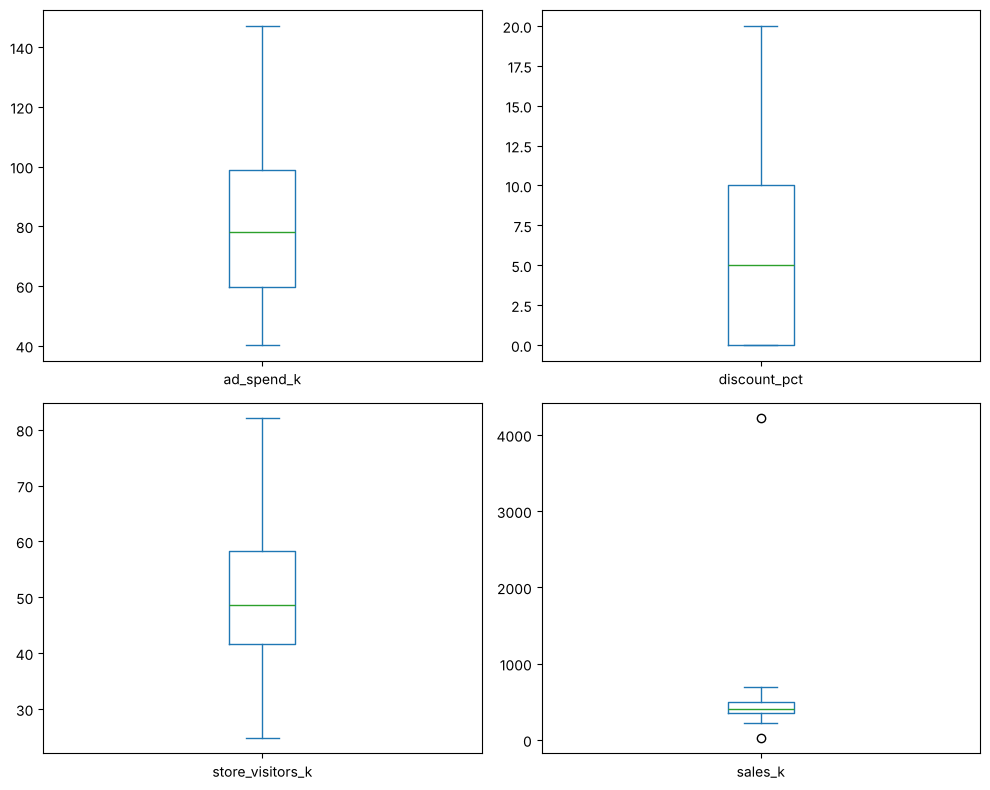

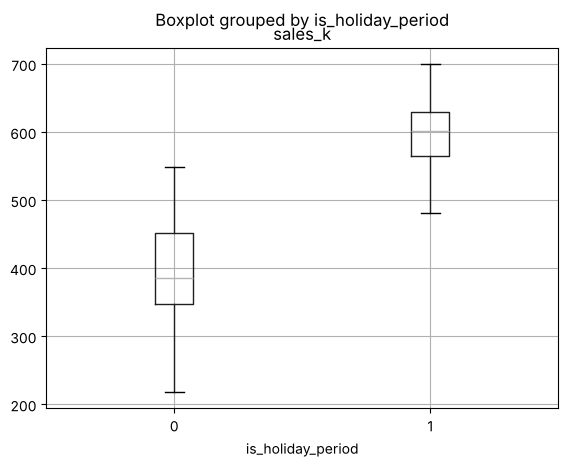

In [7]:
# One boxplot per numeric column
df[["ad_spend_k", "discount_pct", "store_visitors_k", "sales_k"]].plot(
    kind="box", subplots=True, layout=(2, 2), figsize=(10, 8)
)
plt.tight_layout()
plt.show()

# Sales without the two bad rows, split by holiday
df[~df.week.isin([45, 97])].boxplot(column="sales_k", by="is_holiday_period")
plt.show()

**Your answer:**

Only `ad_spend_k` has missing values: 5 weeks (18, 59, 91, 128 and 142).

`sales_k` ranges from 31.5 to 4,215 thousand EGP, and both ends look wrong. Typical weeks sell 350–500k, and the most visitors in any week is 82k. Week 45 sold only 31.5k while 49.6k people came in, which is under 1 EGP per visitor when every other week is about 8–9. Week 97 sold 4,215k from 41k visitors, about 10 times too high. The IQR check flags exactly these two weeks. They also pull the mean (452.5k) well above the median (411.3k) and inflate the standard deviation to 322k.

---
## Task 2: Clean the data

**Goal:** Fix the missing values and remove the two broken weeks.

**Why it matters:** One bad row can bend a whole regression line (slide 18).

**Steps:**
1. Copy `df` into a new DataFrame named `clean`.
2. Fill the missing `ad_spend_k` values with the column's median.
3. Find the two weeks with impossible `sales_k` values. Operations confirmed that one was a system outage and the other a typing error.
4. Keep only the rows where `sales_k` is between 100 and 1500.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Use `.copy()`, `.fillna()`, `.median()` and a boolean filter with `.between()`. Sorting by `sales_k` helps you see the two rows.

</details>

In [8]:
# Task 2: Clean the data
# Create: clean

# 1. Copy df into a new DataFrame named clean
clean = df.copy()

# 2. Fill missing ad_spend_k with the column median
clean["ad_spend_k"] = clean["ad_spend_k"].fillna(clean["ad_spend_k"].median())

# 3. Find the two impossible sales_k values
bad = clean[(clean["sales_k"] < 100) | (clean["sales_k"] > 1500)]
print(bad[["week", "sales_k"]])

# 4. Keep only rows where sales_k is between 100 and 1500
clean = clean[clean["sales_k"].between(100, 1500)]

    week  sales_k
44    45     31.5
96    97   4215.0


In [9]:
# Self-check: just run this cell
check("Two rows removed", lambda: len(clean) == 154)
check("No missing ad spend", lambda: clean["ad_spend_k"].isna().sum() == 0)
check("Sales values look possible", lambda: clean["sales_k"].between(100, 1500).all())
check("Original df was not changed", lambda: len(df) == 156)

✅ Two rows removed
✅ No missing ad spend
✅ Sales values look possible
✅ Original df was not changed


**✍️ Question 2:** Why is it better to investigate these two weeks than to delete any unusual row automatically? Give a business example of an unusual week you should keep.

**Your answer:**

An unusual value is not always a wrong value. Deleting every outlier automatically can throw away the weeks that matter most for planning. Here we only removed weeks 45 and 97 because Operations confirmed one was a system outage and the other a typing error, so neither describes real customer behaviour. Investigating first tells us whether a row is an error or a real event.

A week to keep: Eid al-Fitr or the last week of Ramadan, when sales can jump far above a normal week. That spike is real demand. Deleting it would make the model under-forecast every future holiday and leave stores short of stock and staff.

---
## Task 3: Look at the relationship

**Goal:** See how ad spend and sales move together.

**Why it matters:** A chart often reveals a business pattern before any model does.

**Steps:**
1. Draw a scatter plot with `ad_spend_k` on the x-axis and `sales_k` on the y-axis.
2. Use a different color for holiday and non-holiday weeks.
3. Add axis labels and a legend.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Plot two groups with `plt.scatter`, one filtered on `is_holiday_period == 1` and the other on `== 0`. See the chart on slide 10.

</details>

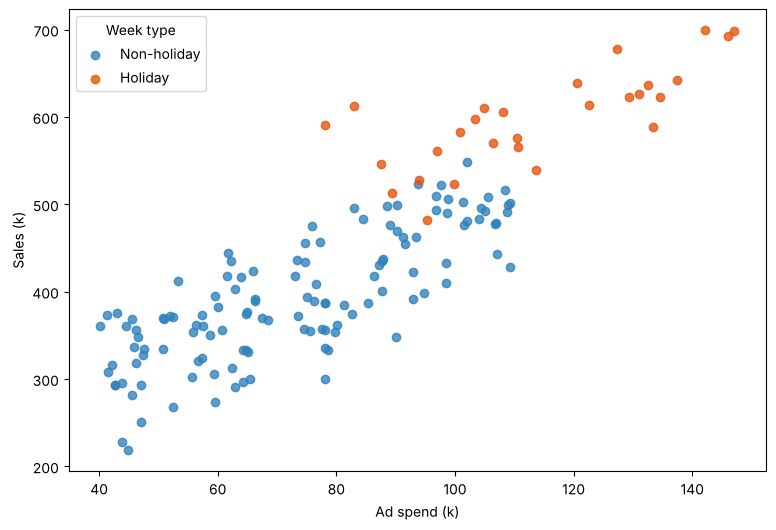

In [10]:
# Task 3: Look at the relationship
# Create: a scatter plot

fig, ax = plt.subplots(figsize=(9, 6))
for flag, label, color in [(0, "Non-holiday", "#3182bd"), (1, "Holiday", "#e6550d")]:
    d = clean[clean.is_holiday_period == flag]
    ax.scatter(d.ad_spend_k, d.sales_k, c=color, label=label, alpha=0.8)

ax.set_xlabel("Ad spend (k)")
ax.set_ylabel("Sales (k)")
ax.legend(title="Week type")
plt.show()

**✍️ Question 3:** Where do the holiday weeks sit on the chart? Could this affect how much credit we give to ads? Explain.

**Your answer:**

Holiday weeks sit in the top-right of the chart. They have both the highest ad spend (about 114k on average vs 73k in normal weeks) and the highest sales (about 599k vs 393k). The company clearly spends more on ads during Ramadan, Eid and year-end, when people would shop more anyway.

Yes, this affects how much credit ads get. A line drawn through all the points mixes two effects: holidays raise sales on their own, and holidays also come with higher ad budgets. The ads-only model cannot tell them apart, so it gives ads credit for part of the holiday boost and overstates what ads really do.

---
## Task 4: Split by time

**Goal:** Train on the past and test on the most recent 30 weeks.

**Why it matters:** A forecast is always about the future, so the test must look like the future.

**Steps:**
1. Put all rows except the last 30 into `train`.
2. Put the last 30 rows into `test`.
3. Print the size of each one.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Do not shuffle here. Use `.iloc` with a negative index. This differs from the random split on slide 9, because this data has an order in time.

</details>

In [11]:
# Task 4: Split by time
# Create: train, test

train = clean.iloc[:-30]   # everything except the last 30 rows
test = clean.iloc[-30:]    # the last 30 rows

print("train:", train.shape)
print("test:", test.shape)

train: (124, 7)
test: (30, 7)


In [12]:
# Self-check: just run this cell
check("Train has 124 rows, test has 30", lambda: len(train) == 124 and len(test) == 30)
check("All test weeks come after all train weeks", lambda: train["week"].max() < test["week"].min())

✅ Train has 124 rows, test has 30
✅ All test weeks come after all train weeks


**✍️ Question 4:** What would go wrong if we shuffled the weeks at random before splitting?

**Your answer:**

The test would no longer look like the future. Training weeks would sit on both sides of each test week, so the model would effectively learn from "the future" (for example week 140) and then be tested on week 139. It would also see almost every holiday season in training. The scores would come out better than what we would get in real life, where we always forecast a week we have not seen yet. A time split gives an honest answer to the question that matters: how well does a model built on the past predict what comes next?

---
## Task 5: Build a simple model

**Goal:** Predict sales from ad spend alone. This is your baseline, Model A.

**Why it matters:** Start simple, so every added feature has to prove its value.

**Steps:**
1. Create `X_train_a` and `X_test_a` holding only the `ad_spend_k` column, as a table.
2. Create `y_train` and `y_test` from `sales_k`.
3. Fit a `LinearRegression` named `model_a`.
4. Save the slope in `slope_a` and print the intercept and slope.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Double brackets keep a table: `df[["col"]]`. The results live in `.intercept_` and `.coef_`. See slide 14.

</details>

In [13]:
# Task 5: Build a simple model
# Create: X_train_a, X_test_a, y_train, y_test, model_a, slope_a

y_train, y_test = train["sales_k"], test["sales_k"]

# Create X_train_a and X_test_a as tables (DataFrames with one column)
X_train_a = train[["ad_spend_k"]]
X_test_a = test[["ad_spend_k"]]

# Fit Model A
model_a = LinearRegression().fit(X_train_a, y_train)

# Save the slope and intercept
intercept_a = model_a.intercept_
slope_a = model_a.coef_[0]

print("Intercept:", intercept_a)
print("Slope:", slope_a)

Intercept: 144.66073807289172
Slope: 3.4930405785268075


In [14]:
# Self-check: just run this cell
check("X is a table with one column", lambda: X_train_a.shape == (124, 1))
check("Model A is fitted", lambda: hasattr(model_a, "coef_"))
check("Slope is positive", lambda: slope_a > 0)

✅ X is a table with one column
✅ Model A is fitted
✅ Slope is positive


**✍️ Question 5:** Complete this sentence using your slope: "Each extra EGP 1,000 of ads goes with about EGP ____ more sales." Why do we say "goes with" and not "causes"?

**Your answer:**

"Each extra EGP 1,000 of ads goes with about **EGP 3,490** more sales." (slope = 3.49)

We say "goes with" because the model only measures how ads and sales move together in past data. It does not prove that ads cause the extra sales. Something else can push both up at the same time: in holiday weeks NileMart spends more on ads *and* customers buy more anyway. Proving cause needs a controlled experiment.

---
## Task 6: Evaluate Model A

**Goal:** Measure how far the forecast misses on the 30 test weeks.

**Why it matters:** Managers plan stock and staff around the size of the error.

**Steps:**
1. Predict the test weeks and save the result in `pred_a`.
2. Compute `mae_a`, `rmse_a` and `r2_a`.
3. Print all three.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Use `M.mean_absolute_error`, `M.root_mean_squared_error` and `M.r2_score`. See slide 16.

</details>

In [15]:
# Task 6: Evaluate Model A
# Create: pred_a, mae_a, rmse_a, r2_a

pred_a = model_a.predict(X_test_a)

mae_a = M.mean_absolute_error(y_test, pred_a)
rmse_a = M.root_mean_squared_error(y_test, pred_a)
r2_a = M.r2_score(y_test, pred_a)

print("MAE :", round(mae_a, 2))
print("RMSE:", round(rmse_a, 2))
print("R2  :", round(r2_a, 3))

MAE : 48.74
RMSE: 61.89
R2  : 0.628


In [16]:
# Self-check: just run this cell
check("One prediction per test week", lambda: len(pred_a) == 30)
check("RMSE is at least as large as MAE", lambda: rmse_a >= mae_a > 0)
check("R² is in a sensible range", lambda: 0.3 < r2_a < 0.9)

✅ One prediction per test week
✅ RMSE is at least as large as MAE
✅ R² is in a sensible range


**✍️ Question 6:** Explain your MAE to the marketing manager in one sentence, in EGP and with no technical words.

**Your answer:**

On a typical week, this forecast is off from actual sales by about **49,000 EGP**, either above or below.

---
## Task 7: Add the features she can plan for

**Goal:** Build Model B with ad spend, discount, holiday period and competitor promotion.

**Why it matters:** Real decisions depend on several factors at once (slide 17).

**Steps:**
1. Create a list named `features` with `ad_spend_k`, `discount_pct`, `is_holiday_period` and `competitor_promo`.
2. Fit `model_b` on the training data.
3. Create `coef_b`, a pandas Series of the coefficients with the feature names as its index, and display it.
4. Compute `pred_b`, `mae_b`, `rmse_b` and `r2_b` on the test weeks.
5. Save the ad spend coefficient in `slope_b`.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Build the Series with `pd.Series(values, index=names)`. You can then read one value by its name.

</details>

In [17]:
# Task 7: Add the features she can plan for
# Create: features, model_b, coef_b, slope_b, pred_b, mae_b, rmse_b, r2_b

features = ["ad_spend_k", "discount_pct", "is_holiday_period", "competitor_promo"]

model_b = LinearRegression().fit(train[features], y_train)

coef_b = pd.Series(model_b.coef_, index=features)
display(coef_b)

pred_b = model_b.predict(test[features])
mae_b = M.mean_absolute_error(y_test, pred_b)
rmse_b = M.root_mean_squared_error(y_test, pred_b)
r2_b = M.r2_score(y_test, pred_b)
print("MAE :", round(mae_b, 2))
print("RMSE:", round(rmse_b, 2))
print("R2  :", round(r2_b, 3))

slope_b = coef_b["ad_spend_k"]

ad_spend_k            2.594847
discount_pct          5.163568
is_holiday_period    98.956762
competitor_promo    -42.463316
dtype: float64

MAE : 23.31
RMSE: 33.55
R2  : 0.891


In [18]:
# Self-check: just run this cell
check("Four features used", lambda: len(features) == 4 and len(coef_b) == 4)
check("Model B beats Model A on test MAE", lambda: mae_b < mae_a)
check("Competitor promotions reduce sales", lambda: coef_b["competitor_promo"] < 0)
check("Ad slope is smaller than in Model A", lambda: slope_b < slope_a)

✅ Four features used
✅ Model B beats Model A on test MAE
✅ Competitor promotions reduce sales
✅ Ad slope is smaller than in Model A


**✍️ Question 7:** Interpret the `is_holiday_period` and `competitor_promo` coefficients in plain business language.

**Your answer:**

- **`is_holiday_period` = +99:** in a Ramadan, Eid or year-end week, sales are about **EGP 99,000 higher** than in a normal week with the same ad spend, discount and competitor activity.
- **`competitor_promo` = −42:** when the main competitor runs a promotion, NileMart sells about **EGP 42,000 less** that week, with everything else the same.

**✍️ Question 8:** The ad spend slope dropped between Model A and Model B. Using your chart from Task 3, explain why.

**Your answer:**

The slope fell from 3.49 to 2.59 because Model A was giving ads credit for the holiday boost. In the Task 3 chart, holiday weeks have both the biggest ad budgets and the biggest sales. With ads as its only input, Model A could explain those high holiday sales only through ad spend.

Model B has a separate holiday feature, so it can assign the holiday boost to the holiday itself. What remains for ads is a smaller, more honest effect: about EGP 2,590 more sales per extra EGP 1,000 of ads.

---
## Task 8: Compare the models and inspect the errors

**Goal:** Put both models side by side, then look at where Model B still misses.

**Why it matters:** A single score can hide a repeating problem (slide 16).

**Steps:**
1. Create a DataFrame named `results` with one row per model and the columns MAE, RMSE and R².
2. Compute `errors_b`, which is actual minus predicted for Model B.
3. Plot `errors_b` as bars against the test `week`, with a horizontal line at 0.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Build `results` from a dictionary with `pd.DataFrame(data, index=[...])`. Use `plt.bar` and `plt.axhline(0)`.

</details>

,MAE,RMSE,R²
Model A,48.743,61.891,0.628
Model B,23.313,33.554,0.891


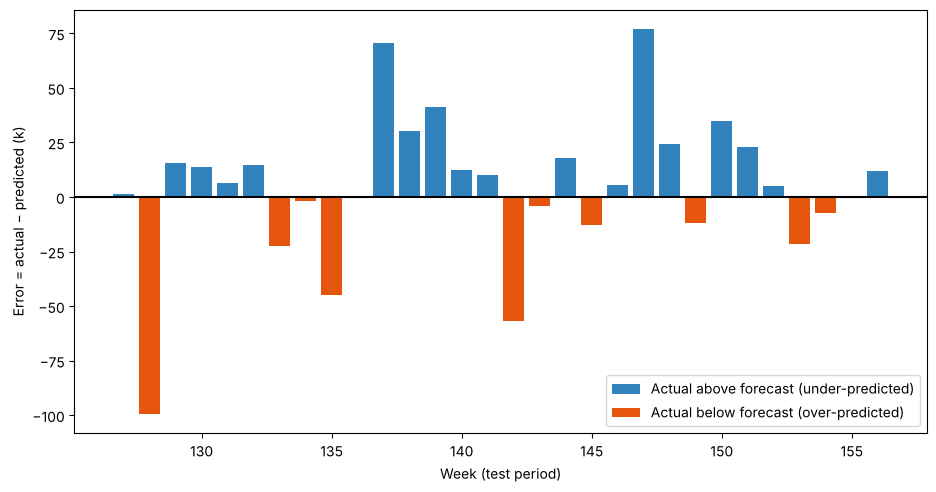

In [19]:
# Task 8: Compare the models and inspect the errors
# Create: results, errors_b, a bar chart

results = pd.DataFrame(
    {"MAE": [mae_a, mae_b], "RMSE": [rmse_a, rmse_b], "R²": [r2_a, r2_b]},
    index=["Model A", "Model B"],
).round(3)
display(results)

errors_b = y_test - pred_b
pos = errors_b >= 0

plt.figure(figsize=(11, 5.5))
plt.bar(test["week"][pos], errors_b[pos], color="#3182bd",
        label="Actual above forecast (under-predicted)")
plt.bar(test["week"][~pos], errors_b[~pos], color="#e6550d",
        label="Actual below forecast (over-predicted)")
plt.axhline(0, color="black")
plt.xlabel("Week (test period)")
plt.ylabel("Error = actual − predicted (k)")
plt.legend()
plt.show()

In [20]:
# Self-check: just run this cell
check("Results table has two models", lambda: results.shape[0] == 2)
check("One error per test week", lambda: len(errors_b) == 30)

✅ Results table has two models
✅ One error per test week


**✍️ Question 9:** By how much did Model B reduce the MAE compared with Model A? Do the errors look random around zero, or do you see a pattern?

**Your answer:**

Model B cut the MAE from **48.7k to 23.3k EGP**, a drop of about **25.4k (52%)**. RMSE fell from 61.9k to 33.6k and R² rose from 0.63 to 0.89.

The errors are mostly scattered around zero, but not perfectly random:
- They lean slightly positive. 18 of 30 weeks are under-predicted, and the average error is about +4.4k, so the model is a little cautious.
- The two largest misses are **week 128 (−99k)** and **week 142 (−57k)**. Both are weeks whose missing ad spend we filled with the median (78k). Those weeks probably spent less than that, so the model over-forecast them. The cleaning choice shows up directly in the errors.
- Some larger misses come in short runs (weeks 137–139 and 147–150), which hints at something the model does not capture, such as local events or the season.

---
## Task 9: Spot the leak

**Goal:** Add `store_visitors_k` to Model B, and name the result Model C. Then decide whether to use it.

**Why it matters:** Leakage produces great scores in the lab and useless forecasts in real life.

**Steps:**
1. Fit `model_c` on the Model B features plus `store_visitors_k`.
2. Compute `r2_c` and `mae_c` on the test weeks.
3. Print them next to the Model B values.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Create a new list with `features + ["store_visitors_k"]`.

</details>

In [21]:
# Task 9: Spot the leak
# Create: model_c, r2_c, mae_c

features_c = features + ["store_visitors_k"]
model_c = LinearRegression().fit(train[features_c], y_train)

pred_c = model_c.predict(test[features_c])
r2_c = M.r2_score(y_test, pred_c)
mae_c = M.mean_absolute_error(y_test, pred_c)

print(f"Model B: R2={r2_b:.3f}  MAE={mae_b:.2f}")
print(f"Model C: R2={r2_c:.3f}  MAE={mae_c:.2f}")

Model B: R2=0.891  MAE=23.31
Model C: R2=0.987  MAE=9.69


In [22]:
# Self-check: just run this cell
check("Model C uses five features", lambda: model_c.coef_.shape[0] == 5)
check("Model C scores higher than Model B", lambda: r2_c > r2_b)

✅ Model C uses five features
✅ Model C scores higher than Model B


**✍️ Question 10:** Model C looks much better. Should the manager use it to plan next week's budget? Explain, thinking about what she knows *before* the week starts.

**Your answer:**

No. Model C's score (R² 0.99, MAE 9.7k) is not achievable in real use, because it relies on **store visitors, which are only known after the week ends**. When the manager sets next week's budget, she knows the ad spend, discount, holiday calendar and maybe the competitor's plans, but not how many people will walk in. Visitors are almost a direct measure of the sales outcome itself (sales are about 8.5 EGP per visitor every week), so the model is effectively reading the answer. This is data leakage.

Model C could also mislead her about ads. Once visitors are included, the ad slope drops to about 0.28. Ads work mostly *by* bringing in visitors, so Model C would make ads look almost useless. She should plan with Model B.

---
## Task 10: Is one more EGP of ads worth it?

**Goal:** Turn the slope into a money decision.

**Why it matters:** Sales are not profit. NileMart keeps a **30% gross margin** on sales.

**Steps:**
1. Compute `return_a`, the gross profit from one extra EGP using `slope_a`.
2. Compute `return_b` the same way using `slope_b`.
3. Print both. A value above 1 means one extra EGP of ads pays for itself.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Slope is sales per one unit of ads, and both are in EGP thousand. Multiply it by the margin.

</details>

In [23]:
# Task 10: Is one more EGP of ads worth it?
# Create: return_a, return_b

margin = 0.30

return_a = slope_a * margin
return_b = slope_b * margin

print("Model A return per EGP:", round(return_a, 3))
print("Model B return per EGP:", round(return_b, 3))

Model A return per EGP: 1.048
Model B return per EGP: 0.778


In [24]:
# Self-check: just run this cell
check("Model A return is computed", lambda: 0.5 < return_a < 2)
check("Model B return is computed", lambda: 0.5 < return_b < 2)

✅ Model A return is computed
✅ Model B return is computed


**✍️ Question 11:** What decision does each model suggest? Which one do you trust more, and why? What test could the company run to measure the true effect of ads?

**Your answer:**

- **Model A** (return 1.05): each extra EGP of ads returns about 1.05 EGP in gross profit, so it suggests ads roughly pay for themselves, and spending more looks slightly worthwhile.
- **Model B** (return 0.78): each extra EGP of ads returns only about 0.78 EGP, so ads lose about 22 piasters per pound. It suggests **not** raising the budget.

I trust **Model B** more. Model A mixes the holiday effect into the ad effect, and Model B corrects for that and makes test errors half as large. Model B is still only a correlation, though: other unrecorded things could also move with ad spend.

To measure the true effect, the company could run a **controlled experiment (A/B test)**: randomly pick some weeks or regions to receive extra ad spend and others to keep the normal budget, then compare sales. Random assignment removes the holiday and season effects and isolates what ads truly do.

---
## Task 11: Plan next week

**Goal:** Forecast sales under three budgets, then try one extreme budget.

**Why it matters:** This is how the model gets used in the planning meeting.

**Steps:**
1. Create a DataFrame named `plans` with the Model B feature columns and three rows: ad spend of 60, 80 and 100. Use a 10% discount, no holiday and a competitor promotion in all three.
2. Add a column named `forecast` with Model B's predictions.
3. Create `extreme` for a single plan with the same settings and 400 in ad spend, then save its forecast in `extreme_forecast`.
4. Print the largest ad spend in the training data.

<details><summary><b>Hint (click only if you are stuck)</b></summary>

Build `plans` from a dictionary, and predict using `plans[features]`, so the column order matches training.

</details>

In [25]:
# Task 11: Plan next week
# Create: plans, extreme, extreme_forecast

plans = pd.DataFrame({
    "ad_spend_k": [60, 80, 100],
    "discount_pct": 10,
    "is_holiday_period": 0,
    "competitor_promo": 1,
})
plans["forecast"] = model_b.predict(plans[features])

extreme = pd.DataFrame({"ad_spend_k": [400], "discount_pct": 10,
                        "is_holiday_period": 0, "competitor_promo": 1})
extreme_forecast = model_b.predict(extreme[features])[0]

print(plans)
print("Extreme plan (400k ads) forecast:", round(extreme_forecast, 1))
print("Largest ad spend in training:", train["ad_spend_k"].max())

   ad_spend_k  discount_pct  is_holiday_period  competitor_promo    forecast
0          60            10                  0                 1  345.712009
1          80            10                  0                 1  397.608954
2         100            10                  0                 1  449.505899
Extreme plan (400k ads) forecast: 1228.0
Largest ad spend in training: 147.1


In [26]:
# Self-check: just run this cell
check("Three plans with forecasts", lambda: len(plans) == 3 and "forecast" in plans.columns)
check("More ads give a higher forecast", lambda: plans["forecast"].is_monotonic_increasing)
check("Extreme forecast is computed", lambda: extreme_forecast > plans["forecast"].max())

✅ Three plans with forecasts
✅ More ads give a higher forecast
✅ Extreme forecast is computed


**✍️ Question 12:** Would you trust the forecast for 400 thousand in ads? Explain using slide 18.

**Your answer:**

No. The model forecasts about **1,228k EGP** of sales for 400k of ads, but the largest ad spend it ever saw in training was **147.1k**. Slide 18 warns against extrapolation: a regression line is only reliable inside the range of the data it learned from. Beyond that range, the model simply extends the straight line. In reality, ads have diminishing returns: the audience saturates, people only buy so much food in a week, and stores have limited capacity. 400k is almost three times anything observed, so the forecast is a guess that is almost certainly too high.

---
## Final deliverable: your recommendation
Write a short memo to the marketing manager in **5 sentences at most**. Include:
1. Which model you recommend, and its typical error in EGP
2. What the model says about spending more on ads
3. One risk or limitation
4. One next step

**Your memo:**

*I recommend Model B, which forecasts weekly sales from ad spend, discount, holidays and competitor promotions; it is typically off by about EGP 23,000 a week. It shows each extra EGP 1,000 of ads goes with about EGP 2,590 more sales, which at our 30% margin returns only about 0.78 EGP in profit per EGP spent, so raising the ad budget does not pay for itself. The main limitation is that this is a correlation, and the model has only seen budgets up to about EGP 147,000, so it cannot be trusted for much larger budgets. As a next step, we should run a controlled test that randomly varies ad spend across weeks or regions to measure the true effect. Until then, I suggest keeping the ad budget at its current level.*

---
## Before you submit
- [x] All self-checks show ✅
- [x] All questions are answered in your own words
- [x] **Restart & Run All** runs from top to bottom with no errors
- [x] Your memo is 5 sentences at most

**Decision tree**

In [27]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Pick depth and leaf size on the training data only, respecting time order
grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    {"max_depth": [2, 3, 4, 5, 6], "min_samples_leaf": [3, 5, 10]},
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error",
)
grid.fit(train[features], y_train)
tree = grid.best_estimator_            # best: max_depth=6, min_samples_leaf=3

# Score on the test weeks
pred_tree = tree.predict(test[features])
mae_t = M.mean_absolute_error(y_test, pred_tree)
rmse_t = M.root_mean_squared_error(y_test, pred_tree)
r2_t = M.r2_score(y_test, pred_tree)

# Which features does it use?
print(grid.best_params_)
print(pd.Series(tree.feature_importances_, index=features))

{'max_depth': 6, 'min_samples_leaf': 3}
ad_spend_k           0.908558
discount_pct         0.050802
is_holiday_period    0.025424
competitor_promo     0.015215
dtype: float64


In [28]:
# Comparison beween model A, B, C and decision tree results

from sklearn.tree import DecisionTreeRegressor

fa = ["ad_spend_k"]
fb = ["ad_spend_k", "discount_pct", "is_holiday_period", "competitor_promo"]
fc = fb + ["store_visitors_k"]

models = {
    "Model A": (LinearRegression(), fa),
    "Model B": (LinearRegression(), fb),
    "Model C (leaks)": (LinearRegression(), fc),
    "Decision tree": (DecisionTreeRegressor(max_depth=6, min_samples_leaf=3,
                                            random_state=42), fb),
}

rows = {}
for name, (m, f) in models.items():
    m.fit(train[f], y_train)
    p = m.predict(test[f])
    rows[name] = [M.mean_absolute_error(y_test, p),
                  M.root_mean_squared_error(y_test, p),
                  M.r2_score(y_test, p)]

all_results = pd.DataFrame(rows, index=["MAE", "RMSE", "R²"]).T.round(3)
display(all_results)

,MAE,RMSE,R²
Model A,48.743,61.891,0.628
Model B,23.313,33.554,0.891
Model C (leaks),9.688,11.638,0.987
Decision tree,43.047,56.107,0.694


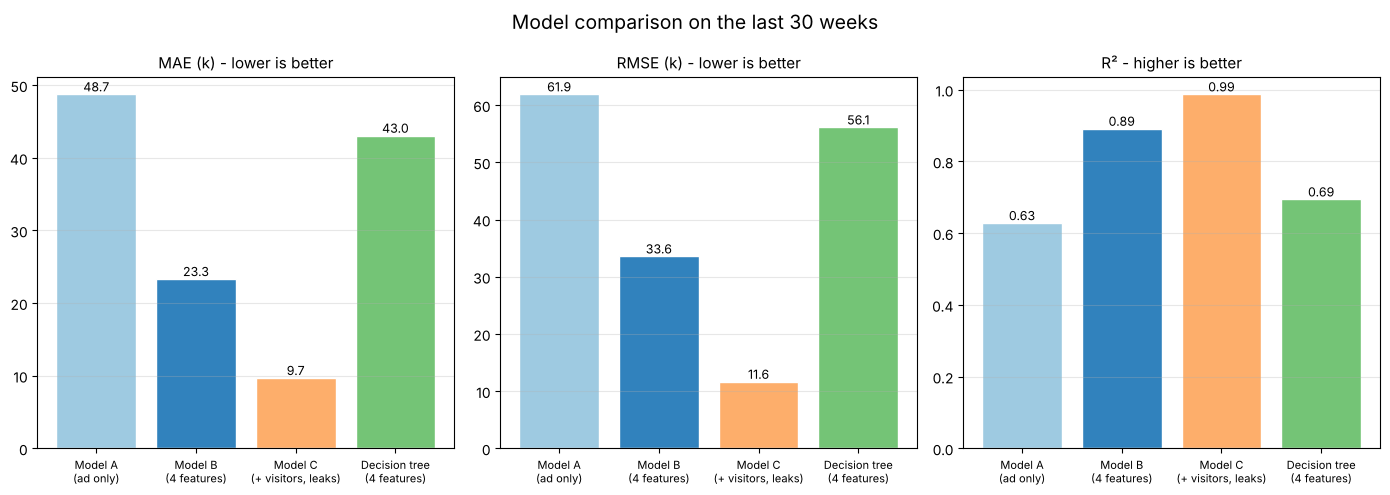

In [29]:
labels = ["Model A\n(ad only)", "Model B\n(4 features)",
          "Model C\n(+ visitors, leaks)", "Decision tree\n(4 features)"]
colors = ["#9ecae1", "#3182bd", "#fdae6b", "#74c476"]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
panels = [("MAE", "MAE (k) - lower is better"),
          ("RMSE", "RMSE (k) - lower is better"),
          ("R²", "R² - higher is better")]

for ax, (col, title) in zip(axes, panels):
    vals = all_results[col].values
    bars = ax.bar(range(4), vals, color=colors, edgecolor="white")
    ax.set_xticks(range(4))
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v,
                f"{v:.2f}" if col == "R²" else f"{v:.1f}",
                ha="center", va="bottom", fontsize=9)

fig.suptitle("Model comparison on the last 30 weeks", fontsize=14)
fig.tight_layout()
plt.show()

In [30]:
# Random Forest

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

features = ["ad_spend_k", "discount_pct", "is_holiday_period", "competitor_promo"]

# Tune on training data only, respecting time order
grid = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=42),
    {"max_depth": [3, 5, 8, None], "min_samples_leaf": [2, 5, 10]},
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
grid.fit(train[features], y_train)
rf = grid.best_estimator_      # best: max_depth=None, min_samples_leaf=2

pred_rf = rf.predict(test[features])
mae_rf = M.mean_absolute_error(y_test, pred_rf)
rmse_rf = M.root_mean_squared_error(y_test, pred_rf)
r2_rf = M.r2_score(y_test, pred_rf)

print(grid.best_params_)
print(pd.Series(rf.feature_importances_, index=features))

{'max_depth': None, 'min_samples_leaf': 2}
ad_spend_k           0.782681
discount_pct         0.057518
is_holiday_period    0.142857
competitor_promo     0.016944
dtype: float64


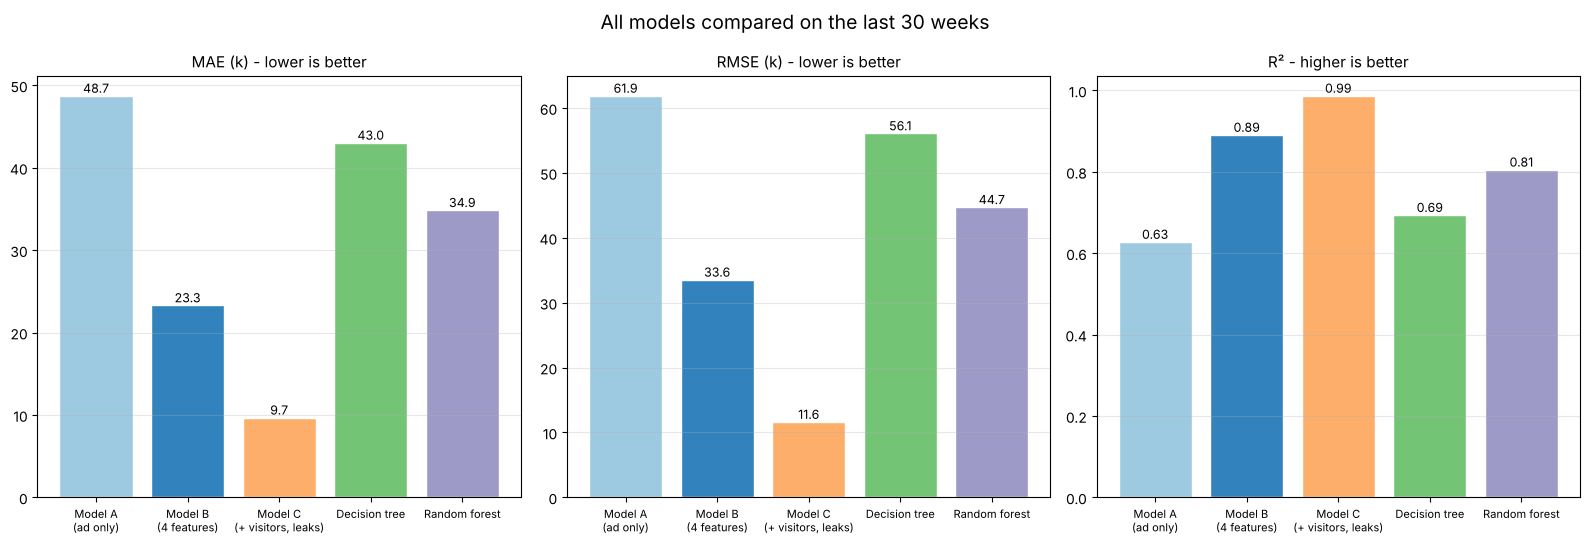

In [31]:
# 1. Add the Random Forest results to the results DataFrame first
all_results.loc["Random forest"] = [mae_rf, rmse_rf, r2_rf]

labels = ["Model A\n(ad only)", "Model B\n(4 features)",
          "Model C\n(+ visitors, leaks)", "Decision tree", "Random forest"]
colors = ["#9ecae1", "#3182bd", "#fdae6b", "#74c476", "#9e9ac8"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
panels = [("MAE", "MAE (k) - lower is better"),
          ("RMSE", "RMSE (k) - lower is better"),
          ("R²", "R² - higher is better")]

for ax, (col, title) in zip(axes, panels):
    vals = all_results[col].values
    bars = ax.bar(range(5), vals, color=colors, edgecolor="white")
    ax.set_xticks(range(5))
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v,
                f"{v:.2f}" if col == "R²" else f"{v:.1f}",
                ha="center", va="bottom", fontsize=9)

fig.suptitle("All models compared on the last 30 weeks", fontsize=14)
fig.tight_layout()
plt.show()

**Recommendations**



1. Model: use Model B (ad spend, discount, holiday and competitor promotion). It is typically off by about 23,000 EGP per week and uses only inputs known in advance.

2. Ads: each extra EGP of ads earns back about 0.78 EGP in gross profit at the 30% margin, so spending more does not pay for itself.

3. Risk: the model has only seen ad budgets up to about 147,000 EGP, so it is unreliable for much larger budgets. Store visitors were rejected because they leak the answer, and the decision tree (MAE 43.0k) and random forest (MAE 34.9k) both scored worse than Model B.

4. Next step: run a controlled test that varies ad spend randomly across weeks or regions, and keep the budget steady until it shows the true effect.


**Saving the best model**

Pick the model with the lowest test error, refit it on all clean weeks, and save it with joblib together with the details needed to use it again. The cell after it loads the file back and makes a forecast to confirm it works.

*In Colab, download `model.joblib` from the folder panel on the left, or copy it to Google Drive.*

In [32]:
import joblib
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Only features known in advance (no store_visitors_k: it leaks)
features = ["ad_spend_k", "discount_pct", "is_holiday_period", "competitor_promo"]

candidates = {
    "Model B (linear)": LinearRegression(),
    "Decision tree": DecisionTreeRegressor(max_depth=6, min_samples_leaf=3, random_state=42),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42),
}

# 1. Fit each on the past, score on the last 30 weeks
scores = {}
for name, m in candidates.items():
    m.fit(train[features], y_train)
    scores[name] = M.mean_absolute_error(y_test, m.predict(test[features]))

# 2. Pick the lowest error
best_name = min(scores, key=scores.get)
print(scores, "->", best_name)

# 3. Refit a fresh copy of the winner on ALL clean weeks
best = type(candidates[best_name])(**candidates[best_name].get_params())
best.fit(clean[features], clean["sales_k"])

# 4. Save the model together with what you need to use it later
joblib.dump({
    "model": best,
    "name": best_name,
    "features": features,
    "test_mae": scores[best_name],
}, "model.joblib")

{'Model B (linear)': 23.312583342853944, 'Decision tree': 43.04722222222223, 'Random forest': 34.87079053190631} -> Model B (linear)


['model.joblib']

In [33]:
art = joblib.load("model.joblib")
plan = pd.DataFrame([[80, 10, 0, 1]], columns=art["features"])
print(art["model"].predict(plan))

[399.9308907]


In [34]:
art = joblib.load("model.joblib")
print(art["name"], "| test MAE:", round(art["test_mae"], 2))

plan = pd.DataFrame([[80, 10, 0, 1]], columns=art["features"])
print(art["model"].predict(plan))

Model B (linear) | test MAE: 23.31
[399.9308907]
